# Analisis Sentimen MBG
## E1 Replikasi Tsabitah et al. vs E2 Random Forest + SMOTE

Notebook ini dibuat sederhana untuk skripsi S1.

**E1 — replikasi operasional paper Tsabitah et al.**  
Cleaning → case folding → normalisasi kata tidak baku → stopword removal → tokenisasi → stemming → TF-IDF → Multinomial Naïve Bayes.

**E2 — metode usulan**  
Preprocessing dan TF-IDF **sama persis dengan E1** → SMOTE **hanya pada training** → Random Forest.

Skenario split: **80:20, 70:30, 60:40**. E1 dan E2 memakai indeks train/test dan feature space TF-IDF yang sama pada setiap split.

Catatan: paper tidak menjelaskan random seed, kamus normalisasi lengkap, parameter TF-IDF, maupun library stopword/stemming. Karena itu detail yang tidak tersedia ditetapkan transparan dalam notebook ini.

## 00 — Instalasi

In [ ]:
!pip -q install Sastrawi imbalanced-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 2.6 MB/s eta 0:00:00


## 01 — Mount Drive, import, konfigurasi

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
from datetime import datetime
from collections import Counter
import hashlib, html, json, re, unicodedata, warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)
from imblearn.over_sampling import SMOTE
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

warnings.filterwarnings('ignore')

ROOT = Path('/content/drive/MyDrive/analisis_sentimen_mbg_effie')
DATASET = ROOT / 'makangratis_valid.csv'
ART = ROOT / 'artefacts-tsabitah-vs-rf-smote'

D_DATA = ART/'00_dataset'
D_SPLIT = ART/'01_splits'
D_PRE = ART/'02_preprocessing'
D_E1 = ART/'03_e1_naive_bayes'
D_E2 = ART/'04_e2_random_forest_smote'
D_CMP = ART/'05_comparison'
D_FIG = ART/'06_figures'
for d in [D_DATA,D_SPLIT,D_PRE,D_E1,D_E2,D_CMP,D_FIG]:
    d.mkdir(parents=True, exist_ok=True)

TEXT_COL='full_text'
LABEL_COL='label'
LABEL_MAP={'N':0,'P':1}
RANDOM_STATE=42
SPLITS={'80_20':0.20,'70_30':0.30,'60_40':0.40}
RF_N_ESTIMATORS=300
SMOTE_K=5

def save_json(obj,path):
    with open(path,'w',encoding='utf-8') as f:
        json.dump(obj,f,ensure_ascii=False,indent=2,default=str)

print('Dataset :', DATASET)
print('Artefak :', ART)

Mounted at /content/drive
Dataset : /content/drive/MyDrive/analisis_sentimen_mbg_effie/makangratis_valid.csv
Artefak : /content/drive/MyDrive/analisis_sentimen_mbg_effie/artefacts-tsabitah-vs-rf-smote


## 02 — Load dan validasi dataset

In [ ]:
assert DATASET.exists(), f'Dataset tidak ditemukan: {DATASET}'
df = pd.read_csv(DATASET)[[TEXT_COL,LABEL_COL]].copy()
df[TEXT_COL] = df[TEXT_COL].fillna('').astype(str)
df[LABEL_COL] = df[LABEL_COL].astype(str).str.strip().str.upper()

unknown = set(df[LABEL_COL].unique()) - set(LABEL_MAP)
assert not unknown, f'Label tidak dikenal: {unknown}'

df.insert(0,'row_id',np.arange(len(df),dtype=int))
df['y'] = df[LABEL_COL].map(LABEL_MAP).astype(int)

save_json({
    'jumlah_data': len(df),
    'distribusi_label': df[LABEL_COL].value_counts().to_dict(),
    'duplikat_teks_persis': int(df[TEXT_COL].duplicated().sum())
}, D_DATA/'dataset_profile.json')

print('Jumlah data:', len(df))
display(df[LABEL_COL].value_counts().rename('jumlah').to_frame())
display(df.head())

Jumlah data: 656


,jumlah
label,
N,533
P,123


,row_id,full_text,label,y
0,0,@iweng01 @akunbarublek @ignasbowo Tpi tujuan a...,N,0
1,1,BI Dukung Program Makan Siang Gratis Asalkan T...,P,1
2,2,@RizkiDimasDwij @masgah_ @Ipaahu La iya dana b...,N,0
3,3,@OposisiCerdas Ya di gaji sama makan siang gra...,N,0
4,4,"@RhendyW @marufins Sama kek stunting, solusiny...",N,0


## 03 — Preprocessing

Tahapan mengikuti yang ditulis paper: cleaning, case folding, normalisasi kata tidak baku, stopword removal, tokenisasi, dan stemming.

Karena kamus normalisasi lengkap paper tidak tersedia, notebook memakai kamus operasional yang eksplisit. **Kamus yang sama dipakai E1 dan E2**, jadi perbandingan algoritma tetap fair.

In [ ]:
NORMALIZATION_MAP = {
    'kek':'seperti','kayak':'seperti',
    'ga':'tidak','gak':'tidak','gk':'tidak','nggak':'tidak','ngga':'tidak','nggk':'tidak','tdk':'tidak',
    'yg':'yang','udah':'sudah','udh':'sudah','kalo':'kalau','klo':'kalau',
    'krn':'karena','karna':'karena','dgn':'dengan','tp':'tapi','tpi':'tapi',
    'jd':'jadi','dapet':'dapat','dpt':'dapat','gimana':'bagaimana','gmn':'bagaimana',
    'bgt':'sangat','banget':'sangat','sgt':'sangat','aja':'saja','sm':'sama','dr':'dari',
    'utk':'untuk','skrg':'sekarang','skrng':'sekarang','pnya':'punya','msh':'masih',
    'blm':'belum','emg':'memang','emang':'memang','trs':'terus','trus':'terus',
    'bener':'benar','beneran':'benar','gue':'saya','gw':'saya','lu':'kamu','lo':'kamu',
    'org':'orang','gtu':'begitu','gitu':'begitu'
}

pd.DataFrame(
    [{'tidak_baku':k,'baku':v} for k,v in NORMALIZATION_MAP.items()]
).sort_values('tidak_baku').to_csv(D_PRE/'normalization_map.csv',index=False)

STOPWORDS = set(StopWordRemoverFactory().get_stop_words())
PRESERVE = {'tidak','tak','bukan','belum','jangan','tanpa','tapi'}
STOPWORDS = STOPWORDS - PRESERVE
stemmer = StemmerFactory().create_stemmer()

def preprocess_text(text):
    text = html.unescape(str(text))
    text = unicodedata.normalize('NFKC', text).lower()
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    text = re.sub(r'@\w+', ' ', text)
    text = re.sub(r'#(\w+)', r' \1 ', text)
    text = re.sub(r'\b\d+\b', ' ', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()

    tokens = re.findall(r'[a-z]+', text)
    normalized=[]
    for t in tokens:
        repl=NORMALIZATION_MAP.get(t,t)
        normalized.extend(re.findall(r'[a-z]+',repl))
    filtered=[t for t in normalized if t not in STOPWORDS]
    return ' '.join(stemmer.stem(t) for t in filtered if t.strip())

prep_path=D_PRE/'dataset_preprocessed.csv'
if prep_path.exists():
    prep=pd.read_csv(prep_path)
else:
    prep=df.copy()
    prep['processed_text']=prep[TEXT_COL].apply(preprocess_text)
    prep.to_csv(prep_path,index=False)

display(prep[['row_id','full_text','processed_text','label']].head(15))

,row_id,full_text,processed_text,label
0,0,@iweng01 @akunbarublek @ignasbowo Tpi tujuan a...,tapi tuju awal makan siang gratis kan baik giz...,N
1,1,BI Dukung Program Makan Siang Gratis Asalkan T...,bi dukung program makan siang gratis asal tak ...,P
2,2,@RizkiDimasDwij @masgah_ @Ipaahu La iya dana b...,la iya dana bos korup proyek makan siang grati...,N
3,3,@OposisiCerdas Ya di gaji sama makan siang gra...,gaji sama makan siang gratis lah,N
4,4,"@RhendyW @marufins Sama kek stunting, solusiny...",sama stunting solusi makan siang gratis tanpa ...,N
5,5,@MrsTitins @ZackXChristy @akunbarublek @ignasb...,tidak baca program apa bagaimana target makan ...,P
6,6,PKS: Kalau Dana BOS Dipakai Makan Siang Gratis...,pks kalau dana bos pakai makan siang gratis te...,N
7,7,https://t.co/LhpkGDxLR6 Bank Indonesia dukung ...,bank indonesia dukung program makan siang gratis,P
8,8,@KangManto123 makan siang gratis receh sampe h...,makan siang gratis receh sampe pakai dana bos,N
9,9,@YandraD31 Buat Gemoy Lover ndak sampai mikir ...,buat gemoy lover ndak mikir situ bang asal imi...,N


## 04 — Split permanen dan sama untuk E1/E2

In [ ]:
registry={}
ids=prep['row_id'].to_numpy()
ys=prep['y'].to_numpy()

for name,test_size in SPLITS.items():
    f=D_SPLIT/f'{name}.npz'
    if f.exists():
        z=np.load(f)
        train_ids=z['train_ids']; test_ids=z['test_ids']
    else:
        train_ids,test_ids=train_test_split(
            ids,test_size=test_size,random_state=RANDOM_STATE,stratify=ys
        )
        train_ids=np.sort(train_ids); test_ids=np.sort(test_ids)
        np.savez_compressed(f,train_ids=train_ids,test_ids=test_ids)
    registry[name]=(train_ids,test_ids)

    tr=prep[prep.row_id.isin(train_ids)]
    te=prep[prep.row_id.isin(test_ids)]
    print(name,
          '| train',len(tr),tr.label.value_counts().to_dict(),
          '| test',len(te),te.label.value_counts().to_dict())

80_20 | train 524 {'N': 426, 'P': 98} | test 132 {'N': 107, 'P': 25}
70_30 | train 459 {'N': 373, 'P': 86} | test 197 {'N': 160, 'P': 37}
60_40 | train 393 {'N': 319, 'P': 74} | test 263 {'N': 214, 'P': 49}


## 05 — Helper evaluasi

In [ ]:
def metrics(y_true,y_pred):
    p,r,f,s=precision_recall_fscore_support(
        y_true,y_pred,labels=[0,1],zero_division=0
    )
    return {
        'accuracy':accuracy_score(y_true,y_pred),
        'precision_weighted':precision_score(y_true,y_pred,average='weighted',zero_division=0),
        'recall_weighted':recall_score(y_true,y_pred,average='weighted',zero_division=0),
        'f1_weighted':f1_score(y_true,y_pred,average='weighted',zero_division=0),
        'macro_f1':f1_score(y_true,y_pred,average='macro',zero_division=0),
        'balanced_accuracy':balanced_accuracy_score(y_true,y_pred),
        'precision_negatif':p[0],'recall_negatif':r[0],'f1_negatif':f[0],'support_negatif':int(s[0]),
        'precision_positif':p[1],'recall_positif':r[1],'f1_positif':f[1],'support_positif':int(s[1])
    }

def save_cm(cm,title,path):
    plt.figure(figsize=(5,4))
    plt.imshow(cm)
    plt.title(title); plt.xlabel('Prediksi'); plt.ylabel('Aktual')
    plt.xticks([0,1],['Negatif','Positif'])
    plt.yticks([0,1],['Negatif','Positif'])
    for i in range(2):
        for j in range(2):
            plt.text(j,i,str(cm[i,j]),ha='center',va='center')
    plt.colorbar(); plt.tight_layout()
    plt.savefig(path,dpi=180,bbox_inches='tight')
    plt.close()

## 06 — Jalankan E1 dan E2

**E1:** `TfidfVectorizer()` → `MultinomialNB()`  
**E2:** TF-IDF yang sama → `SMOTE()` pada training → `RandomForestClassifier(n_estimators=300)`

Tidak ada SMOTE pada testing.

In [ ]:
def run_split(name,train_ids,test_ids):
    work=prep.set_index('row_id')
    tr=work.loc[train_ids].copy()
    te=work.loc[test_ids].copy()

    # Shared TF-IDF
    vec=TfidfVectorizer()
    Xtr=vec.fit_transform(tr.processed_text.fillna(''))
    Xte=vec.transform(te.processed_text.fillna(''))
    ytr=tr.y.to_numpy(); yte=te.y.to_numpy()

    shared=D_SPLIT/name
    shared.mkdir(parents=True,exist_ok=True)
    joblib.dump(vec,shared/'tfidf_vectorizer.joblib')

    # E1
    e1dir=D_E1/name; e1dir.mkdir(parents=True,exist_ok=True)
    nbm=MultinomialNB()
    nbm.fit(Xtr,ytr)
    p1=nbm.predict(Xte)
    m1=metrics(yte,p1)
    m1.update({'split':name,'n_train':len(ytr),'n_test':len(yte),'n_features_tfidf':Xtr.shape[1]})
    joblib.dump(nbm,e1dir/'model_multinomial_nb.joblib')
    save_json(m1,e1dir/'metrics.json')
    with open(e1dir/'classification_report.txt','w') as f:
        f.write(classification_report(yte,p1,target_names=['Negatif','Positif'],digits=4,zero_division=0))
    save_cm(confusion_matrix(yte,p1,labels=[0,1]),f'E1 Naive Bayes — {name}',e1dir/'confusion_matrix.png')
    o1=te.reset_index()[['row_id','full_text','processed_text','label','y']].copy()
    o1['y_pred']=p1; o1['label_pred']=np.where(p1==0,'N','P'); o1['benar']=o1.y==o1.y_pred
    o1.to_csv(e1dir/'predictions.csv',index=False)

    # E2
    e2dir=D_E2/name; e2dir.mkdir(parents=True,exist_ok=True)
    sm=SMOTE(random_state=RANDOM_STATE,k_neighbors=SMOTE_K)
    Xsm,ysm=sm.fit_resample(Xtr,ytr)
    rf=RandomForestClassifier(
        n_estimators=RF_N_ESTIMATORS,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
    rf.fit(Xsm,ysm)
    p2=rf.predict(Xte)
    m2=metrics(yte,p2)
    m2.update({
        'split':name,'n_train_original':len(ytr),'n_train_after_smote':len(ysm),
        'n_test':len(yte),'n_features_tfidf':Xtr.shape[1],
        'class_before_smote':dict(Counter(map(int,ytr))),
        'class_after_smote':dict(Counter(map(int,ysm)))
    })
    joblib.dump(rf,e2dir/'model_random_forest_smote.joblib')
    save_json(m2,e2dir/'metrics.json')
    with open(e2dir/'classification_report.txt','w') as f:
        f.write(classification_report(yte,p2,target_names=['Negatif','Positif'],digits=4,zero_division=0))
    save_cm(confusion_matrix(yte,p2,labels=[0,1]),f'E2 Random Forest + SMOTE — {name}',e2dir/'confusion_matrix.png')
    o2=te.reset_index()[['row_id','full_text','processed_text','label','y']].copy()
    o2['y_pred']=p2; o2['label_pred']=np.where(p2==0,'N','P'); o2['benar']=o2.y==o2.y_pred
    o2.to_csv(e2dir/'predictions.csv',index=False)

    print(
        f'{name} | E1 Acc={m1["accuracy"]:.4f}, MacroF1={m1["macro_f1"]:.4f}, RecallP={m1["recall_positif"]:.4f}'
        f' | E2 Acc={m2["accuracy"]:.4f}, MacroF1={m2["macro_f1"]:.4f}, RecallP={m2["recall_positif"]:.4f}'
    )
    print('SMOTE:',Counter(ytr),'->',Counter(ysm))
    return m1,m2

r1=[]; r2=[]
for name,(trids,teids) in registry.items():
    a,b=run_split(name,trids,teids)
    r1.append(a); r2.append(b)

e1=pd.DataFrame(r1); e2=pd.DataFrame(r2)
e1.to_csv(D_E1/'hasil_e1_semua_split.csv',index=False)
e2.to_csv(D_E2/'hasil_e2_semua_split.csv',index=False)

80_20 | E1 Acc=0.8106, MacroF1=0.4477, RecallP=0.0000 | E2 Acc=0.8409, MacroF1=0.5933, RecallP=0.1600
SMOTE: Counter({np.int64(0): 426, np.int64(1): 98}) -> Counter({np.int64(0): 426, np.int64(1): 426})
70_30 | E1 Acc=0.8122, MacroF1=0.4482, RecallP=0.0000 | E2 Acc=0.8325, MacroF1=0.5861, RecallP=0.1622
SMOTE: Counter({np.int64(0): 373, np.int64(1): 86}) -> Counter({np.int64(0): 373, np.int64(1): 373})
60_40 | E1 Acc=0.8137, MacroF1=0.4486, RecallP=0.0000 | E2 Acc=0.8327, MacroF1=0.5603, RecallP=0.1224
SMOTE: Counter({np.int64(0): 319, np.int64(1): 74}) -> Counter({np.int64(0): 319, np.int64(1): 319})


## 07 — Hasil E1

In [ ]:
display(e1[[
    'split','n_train','n_test','accuracy','precision_weighted','recall_weighted',
    'f1_weighted','macro_f1','balanced_accuracy',
    'recall_negatif','recall_positif','f1_negatif','f1_positif'
]])

,split,n_train,n_test,accuracy,precision_weighted,recall_weighted,f1_weighted,macro_f1,balanced_accuracy,recall_negatif,recall_positif,f1_negatif,f1_positif
0,80_20,524,132,0.810606,0.657082,0.810606,0.725815,0.447699,0.5,1.0,0.0,0.895397,0.0
1,70_30,459,197,0.812183,0.659641,0.812183,0.728007,0.448179,0.5,1.0,0.0,0.896359,0.0
2,60_40,393,263,0.813688,0.662089,0.813688,0.730102,0.448637,0.5,1.0,0.0,0.897275,0.0


## 08 — Hasil E2

In [ ]:
display(e2[[
    'split','n_train_original','n_train_after_smote','n_test',
    'accuracy','precision_weighted','recall_weighted',
    'f1_weighted','macro_f1','balanced_accuracy',
    'recall_negatif','recall_positif','f1_negatif','f1_positif'
]])

,split,n_train_original,n_train_after_smote,n_test,accuracy,precision_weighted,recall_weighted,f1_weighted,macro_f1,balanced_accuracy,recall_negatif,recall_positif,f1_negatif,f1_positif
0,80_20,524,852,132,0.840909,0.867010,0.840909,0.790416,0.593250,0.580000,1.000000,0.160000,0.910638,0.275862
1,70_30,459,746,197,0.832487,0.819831,0.832487,0.785471,0.586055,0.574831,0.987500,0.162162,0.905444,0.266667
2,60_40,393,638,263,0.832700,0.836710,0.832700,0.777437,0.560334,0.558888,0.995327,0.122449,0.906383,0.214286


## 09 — Tabel inti perbandingan

In [ ]:
x=e1.merge(e2,on='split',suffixes=('_e1','_e2'))
cmp=pd.DataFrame({
    'split':x.split,
    'accuracy_e1':x.accuracy_e1,
    'accuracy_e2':x.accuracy_e2,
    'delta_accuracy':x.accuracy_e2-x.accuracy_e1,
    'macro_f1_e1':x.macro_f1_e1,
    'macro_f1_e2':x.macro_f1_e2,
    'delta_macro_f1':x.macro_f1_e2-x.macro_f1_e1,
    'balanced_accuracy_e1':x.balanced_accuracy_e1,
    'balanced_accuracy_e2':x.balanced_accuracy_e2,
    'recall_negatif_e1':x.recall_negatif_e1,
    'recall_negatif_e2':x.recall_negatif_e2,
    'recall_positif_e1':x.recall_positif_e1,
    'recall_positif_e2':x.recall_positif_e2,
    'f1_positif_e1':x.f1_positif_e1,
    'f1_positif_e2':x.f1_positif_e2
})
cmp.to_csv(D_CMP/'perbandingan_e1_vs_e2.csv',index=False)
display(cmp)

,split,accuracy_e1,accuracy_e2,delta_accuracy,macro_f1_e1,macro_f1_e2,delta_macro_f1,balanced_accuracy_e1,balanced_accuracy_e2,recall_negatif_e1,recall_negatif_e2,recall_positif_e1,recall_positif_e2,f1_positif_e1,f1_positif_e2
0,80_20,0.810606,0.840909,0.030303,0.447699,0.593250,0.145551,0.5,0.580000,1.0,1.000000,0.0,0.160000,0.0,0.275862
1,70_30,0.812183,0.832487,0.020305,0.448179,0.586055,0.137876,0.5,0.574831,1.0,0.987500,0.0,0.162162,0.0,0.266667
2,60_40,0.813688,0.832700,0.019011,0.448637,0.560334,0.111697,0.5,0.558888,1.0,0.995327,0.0,0.122449,0.0,0.214286


## 10 — Grafik perbandingan

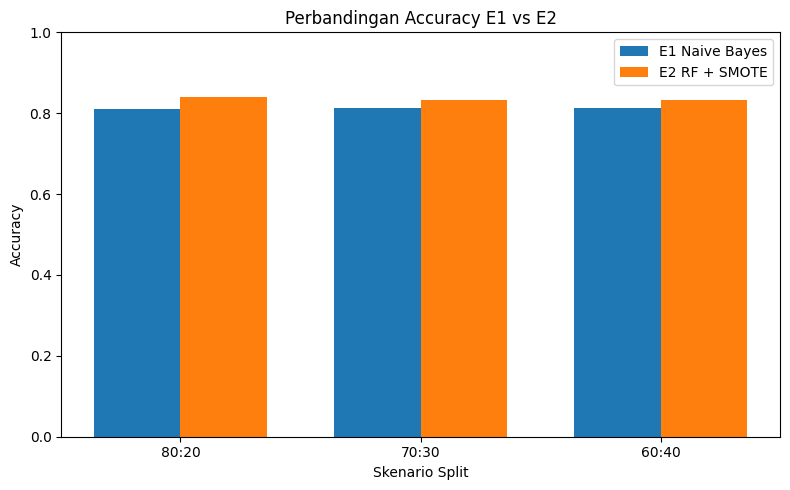

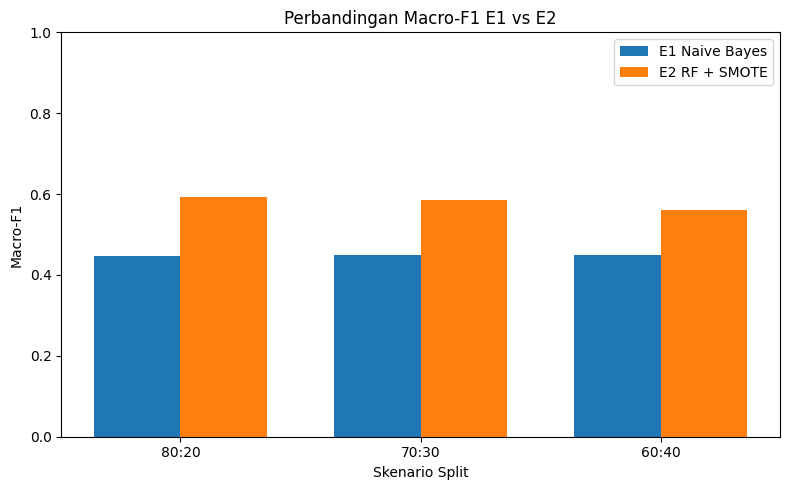

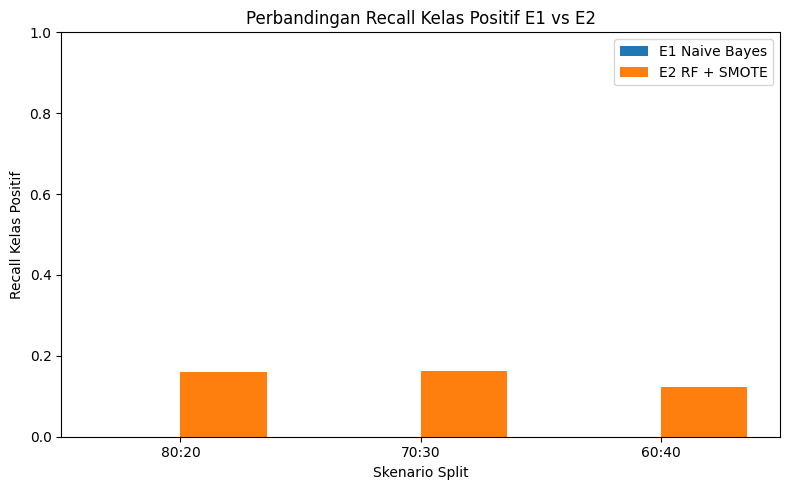

In [ ]:
order=['80_20','70_30','60_40']
g=cmp.set_index('split').loc[order].reset_index()
pos=np.arange(len(g)); w=.36

for metric,title in [
    ('accuracy','Accuracy'),
    ('macro_f1','Macro-F1'),
    ('recall_positif','Recall Kelas Positif')
]:
    plt.figure(figsize=(8,5))
    plt.bar(pos-w/2,g[f'{metric}_e1'],w,label='E1 Naive Bayes')
    plt.bar(pos+w/2,g[f'{metric}_e2'],w,label='E2 RF + SMOTE')
    plt.xticks(pos,['80:20','70:30','60:40'])
    plt.ylim(0,1)
    plt.xlabel('Skenario Split'); plt.ylabel(title)
    plt.title(f'Perbandingan {title} E1 vs E2')
    plt.legend(); plt.tight_layout()
    out=D_FIG/f'perbandingan_{metric}.png'
    plt.savefig(out,dpi=180,bbox_inches='tight')
    plt.show()

## 11 — Angka paper sebagai referensi, bukan hasil notebook

Tsabitah et al. melaporkan:
- Accuracy 89,93%
- Precision 88,64%
- Recall 89,93%
- F1-score 86,42%

Namun paper menyatakan split 80:20 = 524 training + 132 testing, sedangkan confusion matrix yang ditampilkan berjumlah 656 data. Karena itu notebook ini menggunakan hasil evaluasi E1 yang benar-benar dihitung hanya pada testing sebagai hasil replikasi.

In [ ]:
paper_reference={
    'reported_accuracy':0.8993,
    'reported_precision':0.8864,
    'reported_recall':0.8993,
    'reported_f1':0.8642,
    'reported_dataset_size':656,
    'reported_test_80_20':132,
    'reported_confusion_matrix_total':656
}
save_json(paper_reference,D_CMP/'paper_tsabitah_reference.json')
paper_reference

{'reported_accuracy': 0.8993,
 'reported_precision': 0.8864,
 'reported_recall': 0.8993,
 'reported_f1': 0.8642,
 'reported_dataset_size': 656,
 'reported_test_80_20': 132,
 'reported_confusion_matrix_total': 656}

## 12 — Ringkasan akhir

In [ ]:
best_e1=e1.sort_values(['accuracy','macro_f1'],ascending=False).iloc[0]
best_e2=e2.sort_values(['accuracy','macro_f1'],ascending=False).iloc[0]

print('BEST E1')
print('Split:',best_e1['split'])
print('Accuracy:',round(best_e1['accuracy'],4))
print('Macro-F1:',round(best_e1['macro_f1'],4))
print('Recall Positif:',round(best_e1['recall_positif'],4))

print('\nBEST E2')
print('Split:',best_e2['split'])
print('Accuracy:',round(best_e2['accuracy'],4))
print('Macro-F1:',round(best_e2['macro_f1'],4))
print('Recall Positif:',round(best_e2['recall_positif'],4))

print('\nArtefak:',ART)

BEST E1
Split: 60_40
Accuracy: 0.8137
Macro-F1: 0.4486
Recall Positif: 0.0

BEST E2
Split: 80_20
Accuracy: 0.8409
Macro-F1: 0.5933
Recall Positif: 0.16

Artefak: /content/drive/MyDrive/analisis_sentimen_mbg_effie/artefacts-tsabitah-vs-rf-smote


In [ ]:
# ============================================================
# ANALISIS DATA UJI YANG SALAH DIKLASIFIKASIKAN
# ============================================================

all_errors = []

for split_name in SPLITS.keys():

    for experiment_name, experiment_dir in [
        ('E1_Naive_Bayes', D_E1),
        ('E2_Random_Forest_SMOTE', D_E2)
    ]:

        prediction_path = (
            experiment_dir /
            split_name /
            'predictions.csv'
        )

        pred = pd.read_csv(prediction_path)

        # Ambil hanya prediksi yang salah
        salah = pred[pred['benar'] == False].copy()

        salah.insert(
            0,
            'experiment',
            experiment_name
        )

        salah.insert(
            1,
            'split',
            split_name
        )

        # Jenis kesalahan
        salah['jenis_kesalahan'] = np.where(
            (salah['label'] == 'P') &
            (salah['label_pred'] == 'N'),
            'Positif -> Negatif',
            'Negatif -> Positif'
        )

        all_errors.append(salah)


# ============================================================
# GABUNGKAN SEMUA ERROR
# ============================================================

error_analysis = pd.concat(
    all_errors,
    ignore_index=True
)

# Kolom yang paling penting untuk analisis
error_analysis = error_analysis[
    [
        'experiment',
        'split',
        'row_id',
        'full_text',
        'processed_text',
        'label',
        'label_pred',
        'jenis_kesalahan'
    ]
]


# ============================================================
# SIMPAN
# ============================================================

error_path = (
    D_CMP /
    'error_analysis_semua_split.csv'
)

error_analysis.to_csv(
    error_path,
    index=False
)


# ============================================================
# RINGKASAN
# ============================================================

print('=' * 80)
print('JUMLAH DATA UJI YANG SALAH DIKLASIFIKASIKAN')
print('=' * 80)

summary_error = (
    error_analysis
    .groupby(
        [
            'experiment',
            'split',
            'jenis_kesalahan'
        ]
    )
    .size()
    .reset_index(
        name='jumlah'
    )
)

display(summary_error)


print('\nTotal kesalahan per eksperimen dan split:')

display(
    error_analysis
    .groupby(
        [
            'experiment',
            'split'
        ]
    )
    .size()
    .reset_index(
        name='jumlah_salah'
    )
)


# ============================================================
# KHUSUS ERROR E2 — RANDOM FOREST + SMOTE
# ============================================================

error_e2 = error_analysis[
    error_analysis['experiment']
    == 'E2_Random_Forest_SMOTE'
].copy()

error_e2_path = (
    D_CMP /
    'error_analysis_e2_random_forest_smote.csv'
)

error_e2.to_csv(
    error_e2_path,
    index=False
)

print('\nContoh data yang masih salah pada E2:')
display(
    error_e2.head(50)
)

print('\nFile semua error :', error_path)
print('File error E2    :', error_e2_path)

JUMLAH DATA UJI YANG SALAH DIKLASIFIKASIKAN


,experiment,split,jenis_kesalahan,jumlah
0,E1_Naive_Bayes,60_40,Positif -> Negatif,49
1,E1_Naive_Bayes,70_30,Positif -> Negatif,37
2,E1_Naive_Bayes,80_20,Positif -> Negatif,25
3,E2_Random_Forest_SMOTE,60_40,Negatif -> Positif,1
4,E2_Random_Forest_SMOTE,60_40,Positif -> Negatif,43
5,E2_Random_Forest_SMOTE,70_30,Negatif -> Positif,2
6,E2_Random_Forest_SMOTE,70_30,Positif -> Negatif,31
7,E2_Random_Forest_SMOTE,80_20,Positif -> Negatif,21



Total kesalahan per eksperimen dan split:


,experiment,split,jumlah_salah
0,E1_Naive_Bayes,60_40,49
1,E1_Naive_Bayes,70_30,37
2,E1_Naive_Bayes,80_20,25
3,E2_Random_Forest_SMOTE,60_40,44
4,E2_Random_Forest_SMOTE,70_30,33
5,E2_Random_Forest_SMOTE,80_20,21



Contoh data yang masih salah pada E2:


,experiment,split,row_id,full_text,processed_text,label,label_pred,jenis_kesalahan
25,E2_Random_Forest_SMOTE,80_20,28,@AnggaPutraF Lebih baik makan siang ama susu g...,lebih baik makan siang ama susu gratis tidak sih,P,N,Positif -> Negatif
26,E2_Random_Forest_SMOTE,80_20,32,Kalau menurut saya makan siang gratis dikasih ...,kalau makan siang gratis kasih bentuk transfer...,P,N,Positif -> Negatif
27,E2_Random_Forest_SMOTE,80_20,71,"@TirtoID gakpapa, gak masalah yang penting dap...",gakpapa tidak masalah penting makan siang gratis,P,N,Positif -> Negatif
28,E2_Random_Forest_SMOTE,80_20,78,@vanzeiks emang ðŸ’™ aku udah ngga sabar makan...,memang tm aku tidak sabar makan siang gratis m...,P,N,Positif -> Negatif
29,E2_Random_Forest_SMOTE,80_20,93,@kompascom ALANGKAH LUCU. Sebenarnya makan sia...,alangkah lucu benar makan siang gratis program...,P,N,Positif -> Negatif
30,E2_Random_Forest_SMOTE,80_20,119,Senang deh program makan siang gratis sudah di...,senang deh program makan siang gratis buat tes...,P,N,Positif -> Negatif
31,E2_Random_Forest_SMOTE,80_20,130,"Maksi gratis menurut gue bagus bgt, Bagi gue ...",maksi gratis bagus sangat pernah hidup plosok ...,P,N,Positif -> Negatif
32,E2_Random_Forest_SMOTE,80_20,179,@mediajelata @Ipaahu Makan siang gratis bagi s...,makan siang gratis siswa sekolah laksana finla...,P,N,Positif -> Negatif
33,E2_Random_Forest_SMOTE,80_20,222,@hansssolo Dek anda yg iQnya rendah gak bisa m...,dek iqnya rendah tidak tangkap arti sungguh du...,P,N,Positif -> Negatif
34,E2_Random_Forest_SMOTE,80_20,278,Katanya ke rakyat jangan pelit... kok ngga set...,kata rakyat jangan pelit kok tidak tuju ngasih...,P,N,Positif -> Negatif



File semua error : /content/drive/MyDrive/analisis_sentimen_mbg_effie/artefacts-tsabitah-vs-rf-smote/05_comparison/error_analysis_semua_split.csv
File error E2    : /content/drive/MyDrive/analisis_sentimen_mbg_effie/artefacts-tsabitah-vs-rf-smote/05_comparison/error_analysis_e2_random_forest_smote.csv


In [ ]:
# ============================================================
# ANALISIS KONSISTENSI PREDIKSI ANTAR SPLIT
# E2 — RANDOM FOREST + SMOTE
# ============================================================

SPLIT_ORDER = ['80_20', '70_30', '60_40']

all_predictions = []

for split_name in SPLIT_ORDER:

    prediction_path = (
        D_E2 /
        split_name /
        'predictions.csv'
    )

    pred = pd.read_csv(prediction_path)

    # Pastikan kolom benar berbentuk boolean
    if pred['benar'].dtype != bool:
        pred['benar'] = (
            pred['benar']
            .astype(str)
            .str.lower()
            .map({
                'true': True,
                'false': False
            })
        )

    pred['split'] = split_name

    all_predictions.append(
        pred[
            [
                'row_id',
                'full_text',
                'processed_text',
                'label',
                'label_pred',
                'benar',
                'split'
            ]
        ]
    )


# ============================================================
# GABUNGKAN HASIL SEMUA SPLIT
# ============================================================

history = pd.concat(
    all_predictions,
    ignore_index=True
)

history['split_rank'] = history['split'].map({
    '80_20': 1,
    '70_30': 2,
    '60_40': 3
})

history = history.sort_values(
    [
        'row_id',
        'split_rank'
    ]
)


# ============================================================
# BUAT RIWAYAT PER ROW_ID
# ============================================================

records = []

for row_id, group in history.groupby('row_id'):

    group = group.sort_values('split_rank')

    # Hanya masuk analisis jika data tersebut
    # menjadi data testing minimal di 2 split
    if len(group) < 2:
        continue

    base = group.iloc[0]

    split_list = group['split'].tolist()
    correct_list = group['benar'].tolist()
    pred_list = group['label_pred'].tolist()

    jumlah_diuji = len(group)
    jumlah_benar = int(sum(correct_list))
    jumlah_salah = jumlah_diuji - jumlah_benar

    # --------------------------------------------------------
    # Tentukan status konsistensi
    # --------------------------------------------------------

    if jumlah_salah == jumlah_diuji:

        status = 'SELALU SALAH'

    elif jumlah_benar == jumlah_diuji:

        status = 'SELALU BENAR'

    elif (
        correct_list[0] == False
        and True in correct_list[1:]
    ):

        status = 'SALAH -> MENJADI BENAR'

    elif (
        correct_list[0] == True
        and False in correct_list[1:]
    ):

        status = 'BENAR -> MENJADI SALAH'

    else:

        status = 'BERUBAH-UBAH'


    # --------------------------------------------------------
    # Buat history yang mudah dibaca
    # --------------------------------------------------------

    riwayat = []

    for split, benar, prediksi in zip(
        split_list,
        correct_list,
        pred_list
    ):

        kondisi = (
            'BENAR'
            if benar
            else 'SALAH'
        )

        riwayat.append(
            f'{split}: {prediksi} ({kondisi})'
        )


    # --------------------------------------------------------
    # Prediksi per split
    # --------------------------------------------------------

    split_data = {}

    for _, row in group.iterrows():

        s = row['split']

        split_data[f'pred_{s}'] = (
            row['label_pred']
        )

        split_data[f'benar_{s}'] = (
            bool(row['benar'])
        )


    records.append({
        'row_id': row_id,
        'full_text': base['full_text'],
        'processed_text': base['processed_text'],
        'label_aktual': base['label'],

        'jumlah_split_diuji': jumlah_diuji,
        'jumlah_benar': jumlah_benar,
        'jumlah_salah': jumlah_salah,

        'status_konsistensi': status,

        'riwayat_prediksi': ' | '.join(
            riwayat
        ),

        **split_data
    })


# ============================================================
# DATAFRAME HASIL
# ============================================================

consistency = pd.DataFrame(records)


# ============================================================
# URUTKAN
# ============================================================

status_order = {
    'SELALU SALAH': 1,
    'SALAH -> MENJADI BENAR': 2,
    'BENAR -> MENJADI SALAH': 3,
    'BERUBAH-UBAH': 4,
    'SELALU BENAR': 5
}

consistency['status_rank'] = (
    consistency['status_konsistensi']
    .map(status_order)
)

consistency = consistency.sort_values(
    [
        'status_rank',
        'jumlah_split_diuji',
        'row_id'
    ],
    ascending=[
        True,
        False,
        True
    ]
).drop(
    columns=['status_rank']
)


# ============================================================
# 1. DATA YANG SELALU SALAH
# ============================================================

selalu_salah = consistency[
    consistency['status_konsistensi']
    == 'SELALU SALAH'
].copy()


# ============================================================
# 2. DATA YANG SALAH LALU MENJADI BENAR
# ============================================================

menjadi_benar = consistency[
    consistency['status_konsistensi']
    == 'SALAH -> MENJADI BENAR'
].copy()


# ============================================================
# 3. KHUSUS DATA YANG DIUJI DI SEMUA 3 SPLIT
#    DAN SELALU SALAH
# ============================================================

selalu_salah_3_split = consistency[
    (
        consistency['status_konsistensi']
        == 'SELALU SALAH'
    )
    &
    (
        consistency['jumlah_split_diuji']
        == 3
    )
].copy()


# ============================================================
# SIMPAN KE DRIVE
# ============================================================

all_path = (
    D_CMP /
    'konsistensi_prediksi_e2_antar_split.csv'
)

wrong_path = (
    D_CMP /
    'e2_selalu_salah_antar_split.csv'
)

improved_path = (
    D_CMP /
    'e2_salah_menjadi_benar_antar_split.csv'
)

wrong_3_path = (
    D_CMP /
    'e2_selalu_salah_di_3_split.csv'
)

consistency.to_csv(
    all_path,
    index=False
)

selalu_salah.to_csv(
    wrong_path,
    index=False
)

menjadi_benar.to_csv(
    improved_path,
    index=False
)

selalu_salah_3_split.to_csv(
    wrong_3_path,
    index=False
)


# ============================================================
# RINGKASAN
# ============================================================

print('=' * 90)
print('KONSISTENSI PREDIKSI E2 — RANDOM FOREST + SMOTE')
print('=' * 90)

summary = (
    consistency[
        'status_konsistensi'
    ]
    .value_counts()
    .rename_axis('status')
    .reset_index(name='jumlah_data')
)

display(summary)


print(
    '\nData yang SELALU SALAH '
    'pada minimal 2 split:',
    len(selalu_salah)
)

print(
    'Data yang SELALU SALAH '
    'pada ketiga split:',
    len(selalu_salah_3_split)
)

print(
    'Data yang awalnya SALAH '
    'kemudian MENJADI BENAR:',
    len(menjadi_benar)
)


# ============================================================
# TAMPILKAN DATA PALING MENARIK
# ============================================================

print('\n' + '=' * 90)
print('DATA YANG SELALU SALAH')
print('=' * 90)

display(
    selalu_salah[
        [
            'row_id',
            'full_text',
            'label_aktual',
            'jumlah_split_diuji',
            'jumlah_salah',
            'riwayat_prediksi'
        ]
    ].head(50)
)


print('\n' + '=' * 90)
print('DATA YANG SALAH KEMUDIAN MENJADI BENAR')
print('=' * 90)

display(
    menjadi_benar[
        [
            'row_id',
            'full_text',
            'label_aktual',
            'jumlah_split_diuji',
            'riwayat_prediksi'
        ]
    ].head(50)
)


print('\nFile tersimpan:')
print('Semua konsistensi :', all_path)
print('Selalu salah      :', wrong_path)
print('Menjadi benar     :', improved_path)
print('Selalu salah 3x   :', wrong_3_path)

KONSISTENSI PREDIKSI E2 — RANDOM FOREST + SMOTE


,status,jumlah_data
0,SELALU BENAR,161
1,SELALU SALAH,29
2,BENAR -> MENJADI SALAH,4
3,SALAH -> MENJADI BENAR,3



Data yang SELALU SALAH pada minimal 2 split: 29
Data yang SELALU SALAH pada ketiga split: 19
Data yang awalnya SALAH kemudian MENJADI BENAR: 3

DATA YANG SELALU SALAH


,row_id,full_text,label_aktual,jumlah_split_diuji,jumlah_salah,riwayat_prediksi
7,28,@AnggaPutraF Lebih baik makan siang ama susu g...,P,3,3,80_20: N (SALAH) | 70_30: N (SALAH) | 60_40: N...
8,32,Kalau menurut saya makan siang gratis dikasih ...,P,3,3,80_20: N (SALAH) | 70_30: N (SALAH) | 60_40: N...
22,71,"@TirtoID gakpapa, gak masalah yang penting dap...",P,3,3,80_20: N (SALAH) | 70_30: N (SALAH) | 60_40: N...
27,78,@vanzeiks emang ðŸ’™ aku udah ngga sabar makan...,P,3,3,80_20: N (SALAH) | 70_30: N (SALAH) | 60_40: N...
32,93,@kompascom ALANGKAH LUCU. Sebenarnya makan sia...,P,3,3,80_20: N (SALAH) | 70_30: N (SALAH) | 60_40: N...
36,119,Senang deh program makan siang gratis sudah di...,P,3,3,80_20: N (SALAH) | 70_30: N (SALAH) | 60_40: N...
51,179,@mediajelata @Ipaahu Makan siang gratis bagi s...,P,3,3,80_20: N (SALAH) | 70_30: N (SALAH) | 60_40: N...
60,222,@hansssolo Dek anda yg iQnya rendah gak bisa m...,P,3,3,80_20: N (SALAH) | 70_30: N (SALAH) | 60_40: N...
78,278,Katanya ke rakyat jangan pelit... kok ngga set...,P,3,3,80_20: N (SALAH) | 70_30: N (SALAH) | 60_40: N...
98,340,@RaniKancana @ganjarpranowo Lebih memilih maka...,P,3,3,80_20: N (SALAH) | 70_30: N (SALAH) | 60_40: N...



DATA YANG SALAH KEMUDIAN MENJADI BENAR


,row_id,full_text,label_aktual,jumlah_split_diuji,riwayat_prediksi
40,130,"Maksi gratis menurut gue bagus bgt, Bagi gue ...",P,3,80_20: N (SALAH) | 70_30: N (SALAH) | 60_40: P...
135,459,@blantik_pedhet2 internet gratis bagus. makan ...,P,3,80_20: N (SALAH) | 70_30: P (BENAR) | 60_40: N...
4,18,@AnggaPutraF makan siang gratis lebih penting ...,N,2,70_30: P (SALAH) | 60_40: N (BENAR)



File tersimpan:
Semua konsistensi : /content/drive/MyDrive/analisis_sentimen_mbg_effie/artefacts-tsabitah-vs-rf-smote/05_comparison/konsistensi_prediksi_e2_antar_split.csv
Selalu salah      : /content/drive/MyDrive/analisis_sentimen_mbg_effie/artefacts-tsabitah-vs-rf-smote/05_comparison/e2_selalu_salah_antar_split.csv
Menjadi benar     : /content/drive/MyDrive/analisis_sentimen_mbg_effie/artefacts-tsabitah-vs-rf-smote/05_comparison/e2_salah_menjadi_benar_antar_split.csv
Selalu salah 3x   : /content/drive/MyDrive/analisis_sentimen_mbg_effie/artefacts-tsabitah-vs-rf-smote/05_comparison/e2_selalu_salah_di_3_split.csv


# Fokus pembahasan skripsi

Bandingkan E1 dan E2 berdasarkan:
1. Accuracy
2. Macro-F1
3. Balanced Accuracy
4. Recall kelas negatif
5. Recall kelas positif
6. Confusion matrix

**Jangan menyimpulkan E2 lebih buruk hanya karena accuracy sedikit turun.**  
Pada dataset tidak seimbang, peningkatan recall positif dan Macro-F1 dapat menunjukkan bahwa model jauh lebih mampu mengenali kedua kelas.

Seluruh artefak tersimpan di:

`/content/drive/MyDrive/analisis_sentimen_mbg_effie/artefacts-tsabitah-vs-rf-smote/`